# KQC QualityFactorTwoface — six capped spiral λ/4 resonators on one probe line (flip-chip lid) (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/quality_factor_twoface.py` (`QualityFactorTwoface`, default parameters, chip name
"CTest"), © IQM Finland Oy, GPL-3.0
(`other-libs/KQCircuits-main/.../kqcircuits/chips/quality_factor_twoface.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *QualityFactorTwoface*).

KQC's "preliminary class for flip-chip resonators": a probe line from the SMA8 launcher WN (PL-1-IN) to EN
(PL-1-OUT) that drops to y = 5000 µm under the top chip, with six T's at x = 3208 … 7292 µm. From each T's side
arm a finger or gap capacitor feeds a `SpiralResonatorPolygon` (a λ/4 wound inside a 2000 × 500 µm box, shorted at
its far end), alternately below and above the line. With the default `resonator_types = ["capped"] * 6` and
`resonator_faces = [0, 1]` every line is drawn on the bottom chip (face `1t1`); the top chip (face `2b1`) is a
metal lid ("capped") that has only its own KQC frame, and the probe line widens to the capped CPW
(a = 10, b = 10 µm) inside the top-chip box. KQC's face-change nodes on the probe line go to face 0 and back, so they
insert no flip-chip connector with these defaults.

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launcher assignment {8: PL-1-IN,
3: PL-1-OUT}; the probe line path with its two `WaveguideCoplanarTaper`s at the top-chip edge (10/6 ↔ 10/10 µm);
the six `WaveguideCoplanarSplitter`s (lengths 15/15/65 µm, side arm down for even, up for odd resonators) at KQC's
positions; the six `FingerCapacitorSquare`s from KQC's `cap_params` (interdigital 4 × 23.1, 4 × 9.9, 2 × 14.1 µm; gap
10, 21, 28 µm; 10/10 µm on the line side, the resonator's a/b on the other), snapped port `a` to the T's side arm as
KQC aligns them; the resonator lengths 5434 / 5429 / 5374 / 5412 / 5493 / 5589 µm with KQC's widths
(a/b = 10/6, 10/6, 10/6, 20/12, 10/6, 5/3 µm) and KQC's spiral path. Step 14 XORs the chip with a stand-alone KQC build.

**Substituted:** each `SpiralResonatorPolygon` is a Designer route (C*i*.b → shorted free end) whose waypoints are
the centre line KQC's `SpiralResonatorPolygon` computes for the same parameters (built in a scratch layout in the
layout cell). The reason: the spiral's `input_path` / `poly_path` are `DPath` shapes, which `design.json` cannot
carry yet (open request). The route draws the same `WaveguideCoplanar`, and
the LOM sees a λ/4 route to a shorted end.

**Not modelled:** the lid. The LOM is face-agnostic, so the resonators are bare planar λ/4 lines; the top chip lowers
their frequencies (higher ε_eff and an extra ground) and that only comes from the exported FEM jobs.

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in); same assignment |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (28 µm off in y, inside the 50 µm tolerance: no shift) |

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components and
routes → DRC → netlist → LOM → FEM → results back → one design change → fab export → snapshots → summary. Steps
with nothing to act on say so.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (the KQC grid has ≈ 0.9 M holes on 1/0 and 3/0) (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/quality_factor_twoface")  # step-by-step snapshots (build/ is not kept in the repo)
FACES = ["1t1", "2b1"]                                        # KQC resonator_face_ids (bottom chip, lid)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID) and KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn). `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

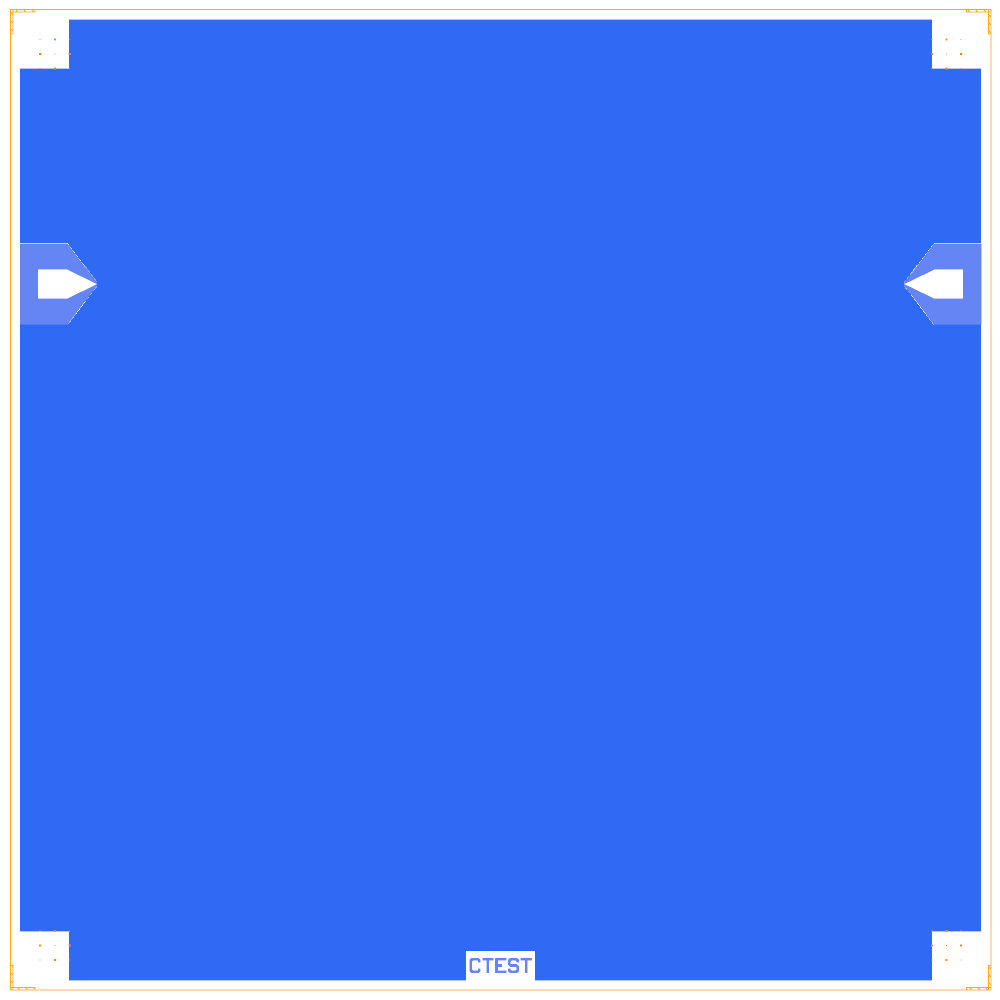

In [4]:
d = Designer("quality_factor_twoface", box=(0, 0, 10000, 10000),
             launchers={"type": "SMA8", "assign": {8: "PL-1-IN", 3: "PL-1-OUT"}},
             chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

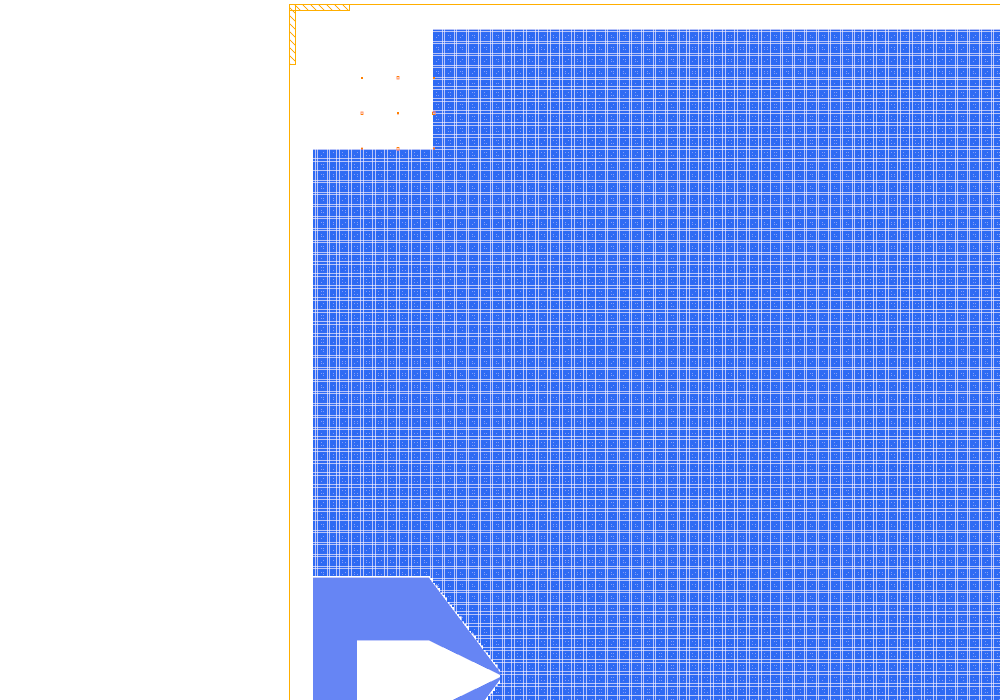

In [5]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.PL-1-IN")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## 5 · Components and 6 · Routes

The elements are placed in the order KQC places them, each on the ports of the previous ones, so components and routes are built together.

**The probe line and the six resonators.** First the six T's on y = 5000 µm (side arm down for even, up for odd resonators) and the coupling capacitors snapped to their side arms; then the probe line from PL-1-IN, tapering to the capped CPW at the top-chip edge, through the six T's and back out to PL-1-OUT; then each spiral λ/4 as a route on KQC's `SpiralResonatorPolygon` centre line (built in a scratch layout by `spiral_path`) to a shorted end.

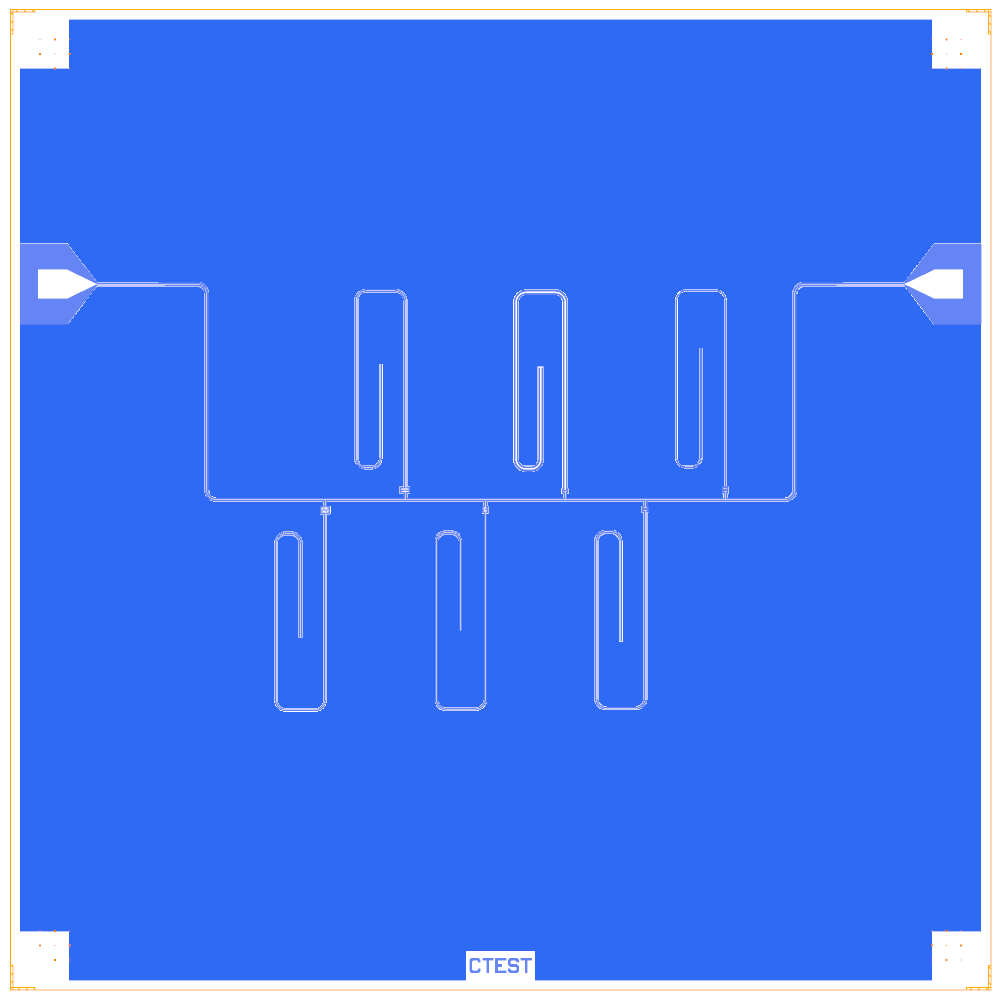

{'PL_in': 4427.49, 'PL_01': 786.67, 'PL_12': 786.67, 'PL_23': 786.67, 'PL_34': 786.67, 'PL_45': 786.67, 'PL_out': 3927.49, 'R0': 5434.0, 'R1': 5429.0, 'R2': 5374.0, 'R3': 5412.0, 'R4': 5493.0, 'R5': 5589.0}


In [6]:
# KQC defaults (QualityFactor lists, QualityFactorTwoface widths and geometry)
res_lengths = [5434, 5429, 5374, 5412, 5493, 5589]
n_fingers, l_fingers = [4, 4, 2, 4, 4, 4], [23.1, 9.9, 14.1, 10, 21, 28]
coupler = ["interdigital", "interdigital", "interdigital", "gap", "gap", "gap"]
res_a, res_b = [10, 10, 10, 20, 10, 5], [6, 6, 6, 12, 6, 3]
a, b, a_c, b_c, r = 10, 6, 10, 10, 100               # chip CPW, capped CPW (a_capped, b_capped), turn radius
top = (1500, 1500, 8500, 8500)                         # top-chip (face 1) box
spiral_h, spiral_w, cap_res, x_indent, wg_indent = 2000, 500, 200, 800, 500
left_x, right_x = top[0] + wg_indent, top[2] - wg_indent
left_c, right_c, mid_y = top[0] + x_indent, top[2] - x_indent, (top[1] + top[3]) / 2
spacing = (right_c - left_c - spiral_w) / 6
xs = [left_c + spiral_w + (i + 0.5) * spacing for i in range(6)]
tee = a_c / 2 + b_c                                    # KQC tee_length; the side arm is 5·a_capped longer


def cap_params(fingers, length, kind):               # KQC util.coupler_lib.cap_params
    p = dict(finger_number=fingers, finger_length=length, finger_gap_end=5, finger_gap=5, finger_width=15,
             ground_padding=10)
    if kind == "gap":
        p |= dict(finger_length=0, finger_gap_end=length, finger_gap=0, finger_width=10)
    return p


def spiral_path(i):
    """Centre line of KQC's SpiralResonatorPolygon for resonator i (local frame, port a at the origin)."""
    from kqcircuits.elements.spiral_resonator_polygon import SpiralResonatorPolygon
    ly = pya.Layout()
    box = [pya.DPoint(cap_res, 0), pya.DPoint(spiral_h, 0), pya.DPoint(spiral_h, -spiral_w), pya.DPoint(cap_res, -spiral_w)]
    cell = SpiralResonatorPolygon.create(ly, input_path=pya.DPath([pya.DPoint(0, 0)], 10), poly_path=pya.DPath(box, 10),
                                         length=res_lengths[i], a=res_a[i], b=res_b[i], r=r, margin=5,
                                         bridge_spacing=0, face_ids=FACES)
    wg = ly.cell(next(cell.each_inst()).cell_index)    # its one WaveguideCoplanar
    path = wg.pcell_parameters_by_name()["path"]
    return [(p.x, p.y) for p in (path.each_point() if hasattr(path, "each_point") else path)]


with d.batch():
    # probe-line T's (KQC splitter nodes: angles [0, 180, side], entered from the left, so rotated 180°)
    for i, x in enumerate(xs):
        d.add(f"T{i}", "WaveguideCoplanarSplitter", at=(x, mid_y), rot=180, angles=[0, 180, 90 if i % 2 == 0 else 270],
              lengths=[tee, tee, tee + 5 * a_c], a=a_c, b=b_c)
    # input capacitors: port a on the T's side arm (KQC align="port_a"), resonator a/b on port b
    for i in range(6):
        d.add(f"C{i}", "FingerCapacitorSquare", snap="a", to=f"T{i}.c", a=a_c, b=b_c, a2=res_a[i], b2=res_b[i],
              face_ids=FACES, **cap_params(n_fingers[i], l_fingers[i], coupler[i]))
    # probe line: launcher → taper to the capped CPW at the top-chip edge → down to y = 5000 → T0 … T5 → back up
    d.route("PL_in", "chip.PL-1-IN", "T0.a", a=a, b=b,
            nodes=[d.waypoint((top[0], 7200), a=a_c, b=b_c), (left_x, 7200), (left_x, mid_y)])
    for i in range(5):
        d.route(f"PL_{i}{i + 1}", f"T{i}.b", f"T{i + 1}.a", a=a_c, b=b_c)
    d.route("PL_out", "T5.b", "chip.PL-1-OUT", a=a_c, b=b_c,
            nodes=[(right_x, mid_y), (right_x, 7200), d.waypoint((top[2] - 100, 7200), a=a, b=b)])

with d.batch():
    # spiral λ/4 resonators: KQC places the spiral at C_i.b with DCplxTrans(1, side-arm angle, mirror = odd i)
    for i in range(6):
        x, y, ang = port_info(d, f"C{i}.b")
        tr = pya.DCplxTrans(1, ang, i % 2 == 1, x, y)
        pts = [tr * pya.DPoint(*p) for p in spiral_path(i)]
        d.route(f"R{i}", f"C{i}.b", Designer.free_end((pts[-1].x, pts[-1].y), term=0), a=res_a[i], b=res_b[i],
                nodes=[(p.x, p.y) for p in pts[1:-1]])

snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

**Sim groups, centring, save.** One eigenmode sim group per resonator (its T, capacitor and spiral, 200 µm margin; the lid in the box). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved.

In [7]:
for i in range(6):
    d.sim_group(f"R{i}", [f"T{i}", f"C{i}", f"R{i}"], margin_um=200, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "quality_factor_twoface.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer quality_factor_twoface: 12 instances, 13 routes, live=False> → examples\designs\kqc\test_chips\quality_factor_twoface.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean: no errors, no warnings and no PDK design warning. `pdk_report` gives KQC's grid ("the original design's own"), the content 28 µm off in y and no junctions.

In [8]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +28) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [9]:
lb = d.lom()
show_netlist(lb)

**8 nodes · 26 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `T0.t` | `T0.t`, `T1.t`, `T2.t`, `T3.t`, `T4.t`, `T5.t`, `C0.a`, `C1.a`, `C2.a`, `C3.a`, `C4.a`, `C5.a`, `chip.PL-1-IN`, `chip.PL-1-OUT` |
| `C0.b` | `C0.b` |
| `C1.b` | `C1.b` |
| `C2.b` | `C2.b` |
| `C3.b` | `C3.b` |
| `C4.b` | `C4.b` |
| `C5.b` | `C5.b` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_C0` | C | `T0.t` – `C0.b` | 10.8 fF |
| `C_C0_a` | C | `T0.t` – `gnd` | 9.7 fF |
| `C_C0_b` | C | `C0.b` – `gnd` | 9.7 fF |
| `C_C1` | C | `T0.t` – `C1.b` | 7.53 fF |
| `C_C1_a` | C | `T0.t` – `gnd` | 8.5 fF |
| `C_C1_b` | C | `C1.b` – `gnd` | 8.5 fF |
| `C_C2` | C | `T0.t` – `C2.b` | 4.12 fF |
| `C_C2_a` | C | `T0.t` – `gnd` | 5.1 fF |
| `C_C2_b` | C | `C2.b` – `gnd` | 5.1 fF |
| `C_C3` | C | `T0.t` – `C3.b` | 3.11 fF |
| `C_C3_a` | C | `T0.t` – `gnd` | 4.3 fF |
| `C_C3_b` | C | `C3.b` – `gnd` | 4.3 fF |
| `C_C4` | C | `T0.t` – `C4.b` | 2.51 fF |
| `C_C4_a` | C | `T0.t` – `gnd` | 5.1 fF |
| `C_C4_b` | C | `C4.b` – `gnd` | 5.1 fF |
| `C_C5` | C | `T0.t` – `C5.b` | 2.32 fF |
| `C_C5_a` | C | `T0.t` – `gnd` | 5.6 fF |
| `C_C5_b` | C | `C5.b` – `gnd` | 5.6 fF |
| `Port_PL-1-IN` | R | `T0.t` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `T0.t` – `gnd` | 50 Ω |
| `R0` | TLres | `C0.b` – `gnd` | lambda/4, 5434 µm, 5.798 GHz |
| `R1` | TLres | `C1.b` – `gnd` | lambda/4, 5429 µm, 5.804 GHz |
| `R2` | TLres | `C2.b` – `gnd` | lambda/4, 5374 µm, 5.863 GHz |
| `R3` | TLres | `C3.b` – `gnd` | lambda/4, 5412 µm, 5.827 GHz |
| `R4` | TLres | `C4.b` – `gnd` | lambda/4, 5493 µm, 5.736 GHz |
| `R5` | TLres | `C5.b` – `gnd` | lambda/4, 5589 µm, 5.634 GHz |

**Unconnected ports:** none

## 9 · LOM simulation

Six linear modes (QuCat): frequency and external κ into the two 50 Ω launchers; no junctions, so no anharmonicity.
These are planar estimates: the LOM is face-agnostic, so the lid is not in them (it lowers the frequencies; only
the FEM jobs see it). `kqc/qualityfactor` has the same six lengths and couplers as straight λ/4s on an uncapped line.

In [10]:
res = simulate_lom(lb, d.design, max_modes=2)
display(Markdown(modes_md(res)))
Q = {m.label: m.f_GHz * 1e3 / m.kappa_MHz for m in res.modes if m.kappa_MHz}
display(Markdown("| mode | Q_ext (LOM) |\n|---|---|\n" + "\n".join(f"| {k} | {v:.3g} |" for k, v in sorted(Q.items()))))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| R5 | resonator | 5.5783 | 0.0652 | 0.0 | R5 1.00 |
| R0 | resonator | 5.6522 | 1.42 | 0.0 | R0 1.00 |
| R4 | resonator | 5.6818 | 0.0456 | 0.0 | R4 1.00 |
| R1 | resonator | 5.6882 | 0.739 | 0.0 | R1 1.00 |
| R3 | resonator | 5.7734 | 0.124 | 0.0 | R3 1.00 |
| R2 | resonator | 5.7945 | 0.226 | 0.0 | R2 1.00 |

| mode | Q_ext (LOM) |
|---|---|
| R0 | 3.98e+03 |
| R1 | 7.7e+03 |
| R2 | 2.56e+04 |
| R3 | 4.65e+04 |
| R4 | 1.25e+05 |
| R5 | 8.56e+04 |

**Here:** six modes from 5.578 (R5) to 5.795 GHz (R2), each on its own line, with Q_ext from 4.0 × 10³ (R0) to 1.25 × 10⁵ (R4): the interdigital couplers (R0–R2) couple more strongly than the gap couplers (R3–R5). The lid is not in these numbers.

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one eigenmode job per resonator (its T, capacitor and spiral): the probe line leaving the box ends in 50 Ω, so the solve gives f_r and Q_ext with the lid.

In [11]:
jobs = send_fem_jobs(DESIGN, analyses=["eigenmode_epr"], run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

6 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| R0 · eigenmode_epr | `build/jobs/quality_factor_twoface_R0_eigenmode_epr` | 1 · edge_lumped · `PL_01`<br>2 · edge_lumped · `PL_in` | `PL_01`, `PL_in` |
| R1 · eigenmode_epr | `build/jobs/quality_factor_twoface_R1_eigenmode_epr` | 1 · edge_lumped · `PL_01`<br>2 · edge_lumped · `PL_12` | `PL_01`, `PL_12` |
| R2 · eigenmode_epr | `build/jobs/quality_factor_twoface_R2_eigenmode_epr` | 1 · edge_lumped · `PL_12`<br>2 · edge_lumped · `PL_23` | `PL_12`, `PL_23` |
| R3 · eigenmode_epr | `build/jobs/quality_factor_twoface_R3_eigenmode_epr` | 1 · edge_lumped · `PL_23`<br>2 · edge_lumped · `PL_34` | `PL_23`, `PL_34` |
| R4 · eigenmode_epr | `build/jobs/quality_factor_twoface_R4_eigenmode_epr` | 1 · edge_lumped · `PL_34`<br>2 · edge_lumped · `PL_45` | `PL_34`, `PL_45` |
| R5 · eigenmode_epr | `build/jobs/quality_factor_twoface_R5_eigenmode_epr` | 1 · edge_lumped · `PL_45`<br>2 · edge_lumped · `PL_out` | `PL_45`, `PL_out` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [12]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for R0 · eigenmode_epr, R1 · eigenmode_epr, R2 · eigenmode_epr, R3 · eigenmode_epr, R4 · eigenmode_epr, R5 · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The coupling capacitor sets Q_ext. Lengthen R0's interdigital fingers from 23.1 to 40 µm: the coupling capacitance
grows, so R0's κ rises (Q_ext falls) and its f_r drops slightly; the other five do not change. The change is made on
a copy (`design_copy`), so `quality_factor_twoface.json` keeps KQC's 23.1 µm.

In [13]:
d2 = design_copy(DESIGN)
d2["C0"].set(finger_length=40)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=2)
m0, m1 = {m.label: m for m in res.modes}, {m.label: m for m in res2.modes}
display(Markdown("**C0 fingers: 23.1 → 40 µm**\n\n| mode | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |"
                     for k in m0 if k in m1)))

**C0 fingers: 23.1 → 40 µm**

| mode | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |
|---|---|---|---|---|
| R5 | 5.5783 | 5.5783 | 0.0652 | 0.0651 |
| R0 | 5.6522 | 5.6325 | 1.42 | 2.65 |
| R4 | 5.6818 | 5.6818 | 0.0456 | 0.0726 |
| R1 | 5.6882 | 5.6882 | 0.739 | 0.714 |
| R3 | 5.7734 | 5.7734 | 0.124 | 0.125 |
| R2 | 5.7945 | 5.7945 | 0.226 | 0.226 |

**Result.** R0 moves from 5.6522 to 5.6325 GHz (−20 MHz) and its κ from 1.42 to 2.65 MHz (Q_ext 4.0 × 10³ → 2.1 × 10³). R4, the nearest mode (30 MHz up), also changes its κ (0.046 → 0.073 MHz) through the shared probe line; the other four do not move.

## 13 · Build and export

**The design file.** `quality_factor_twoface.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/test_chips/quality_factor_twoface.json` rebuilds `build/quality_factor_twoface.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In this run: 1/0 919 066 polygons, 3/0 910 306; cheese source `build`, 919 060 holes (the bottom chip). The lid draws no shapes of its own here (only KQC's frame did), so there is no 800/0. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/quality_factor_twoface.json` writes the complete file.

In [14]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 919066 |
| 3/0 | M3 | 910306 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 919060 holes on the mask.

→ `build/quality_factor_twoface_fab.oas`

## 14 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and R0's coupler on its T in the **fab view** (the mask from step 13: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

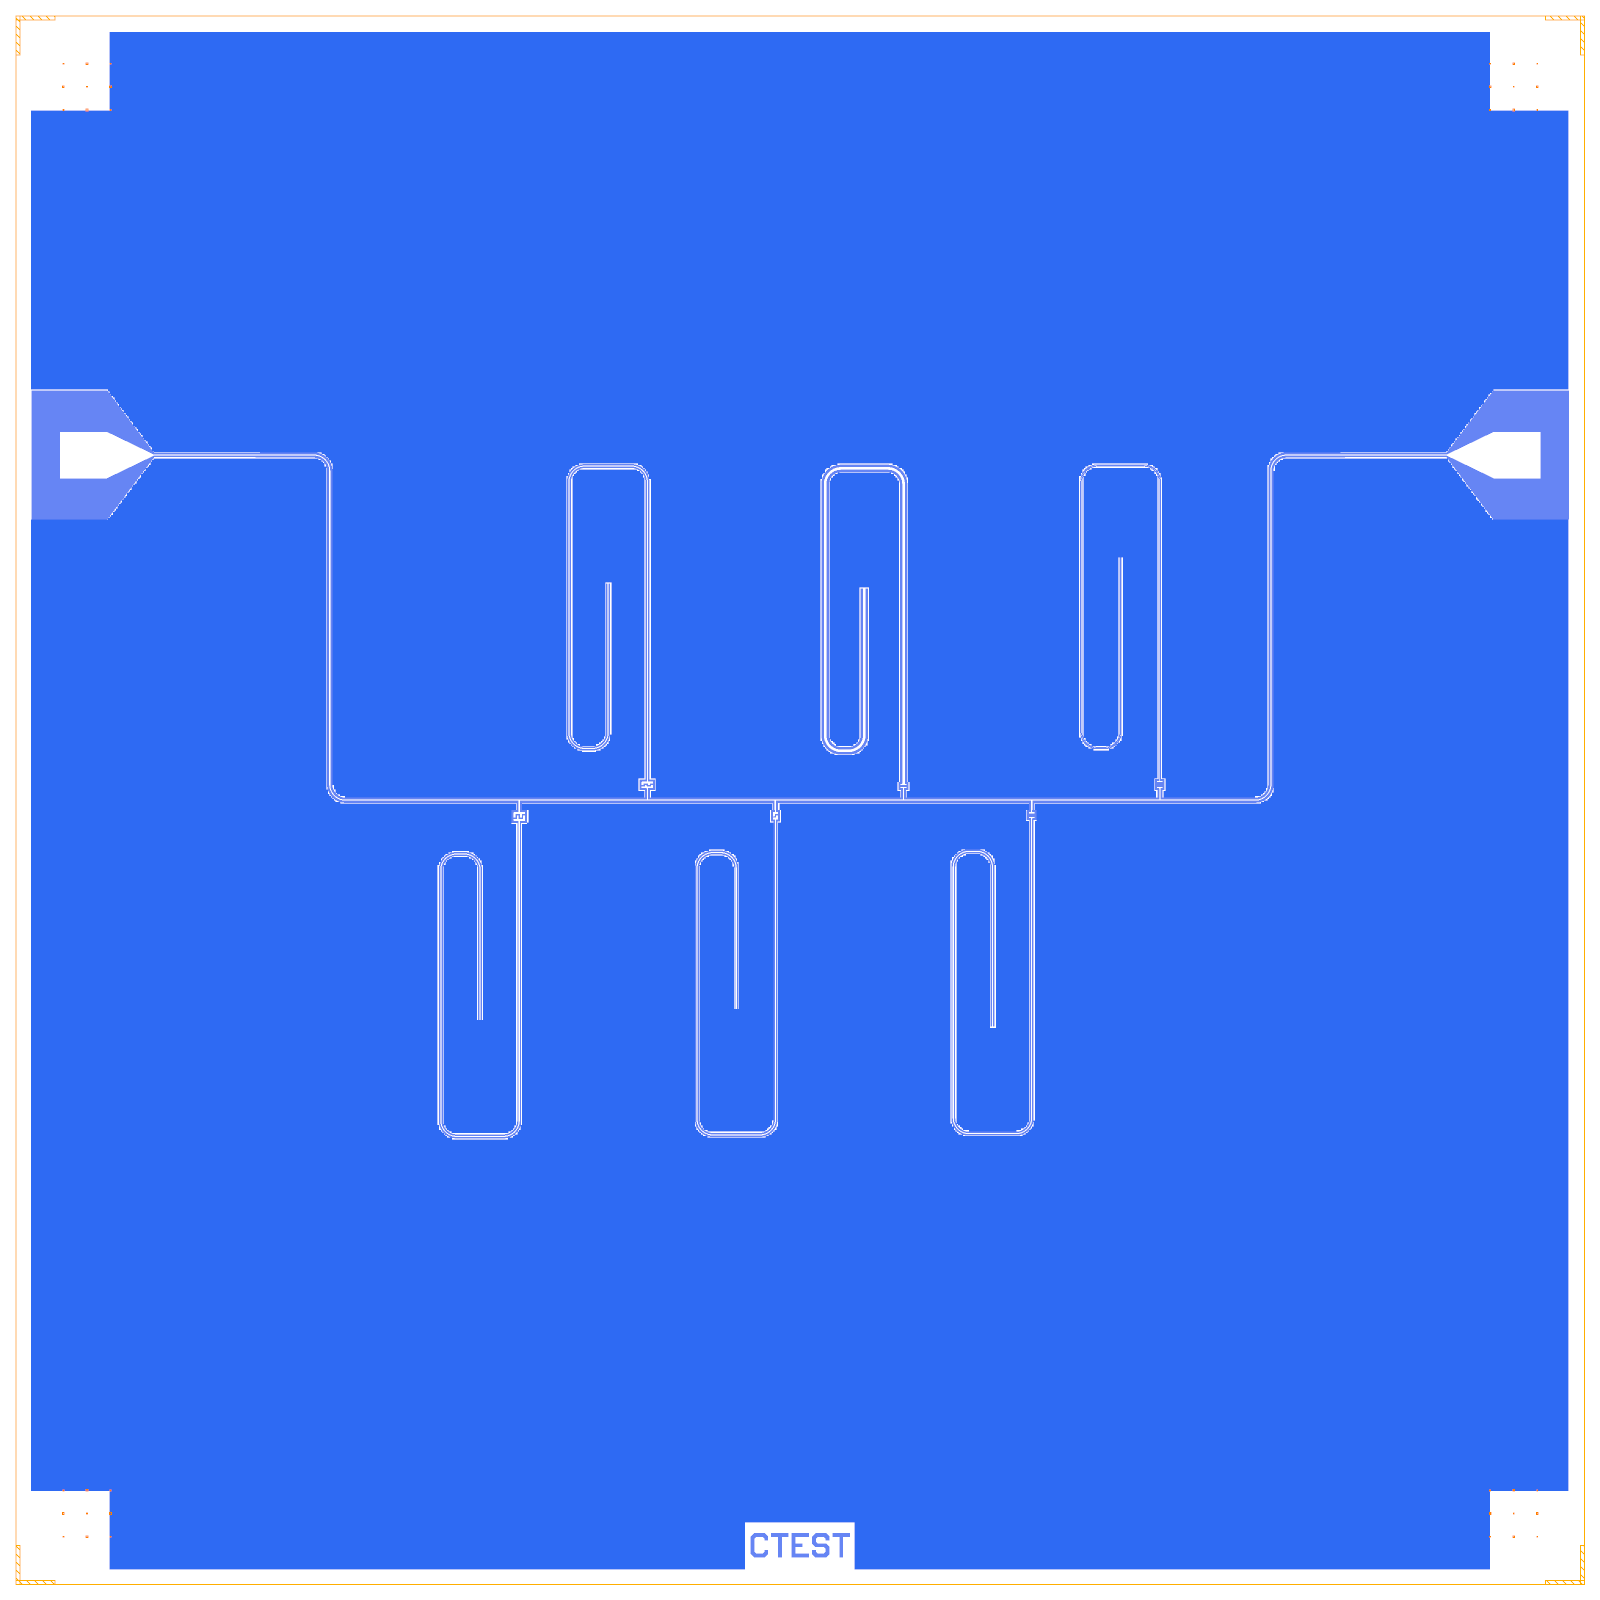

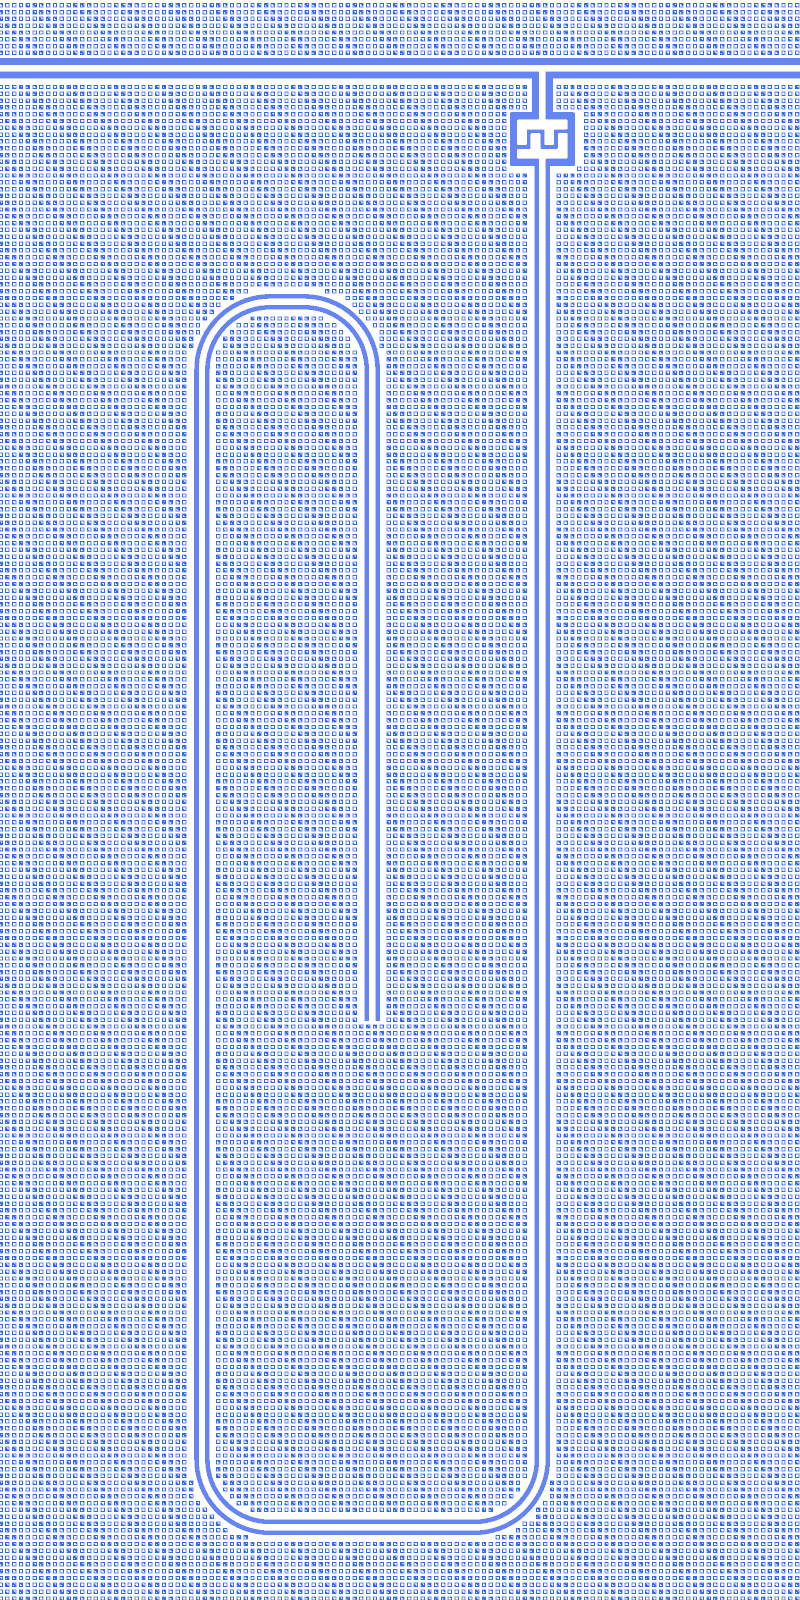

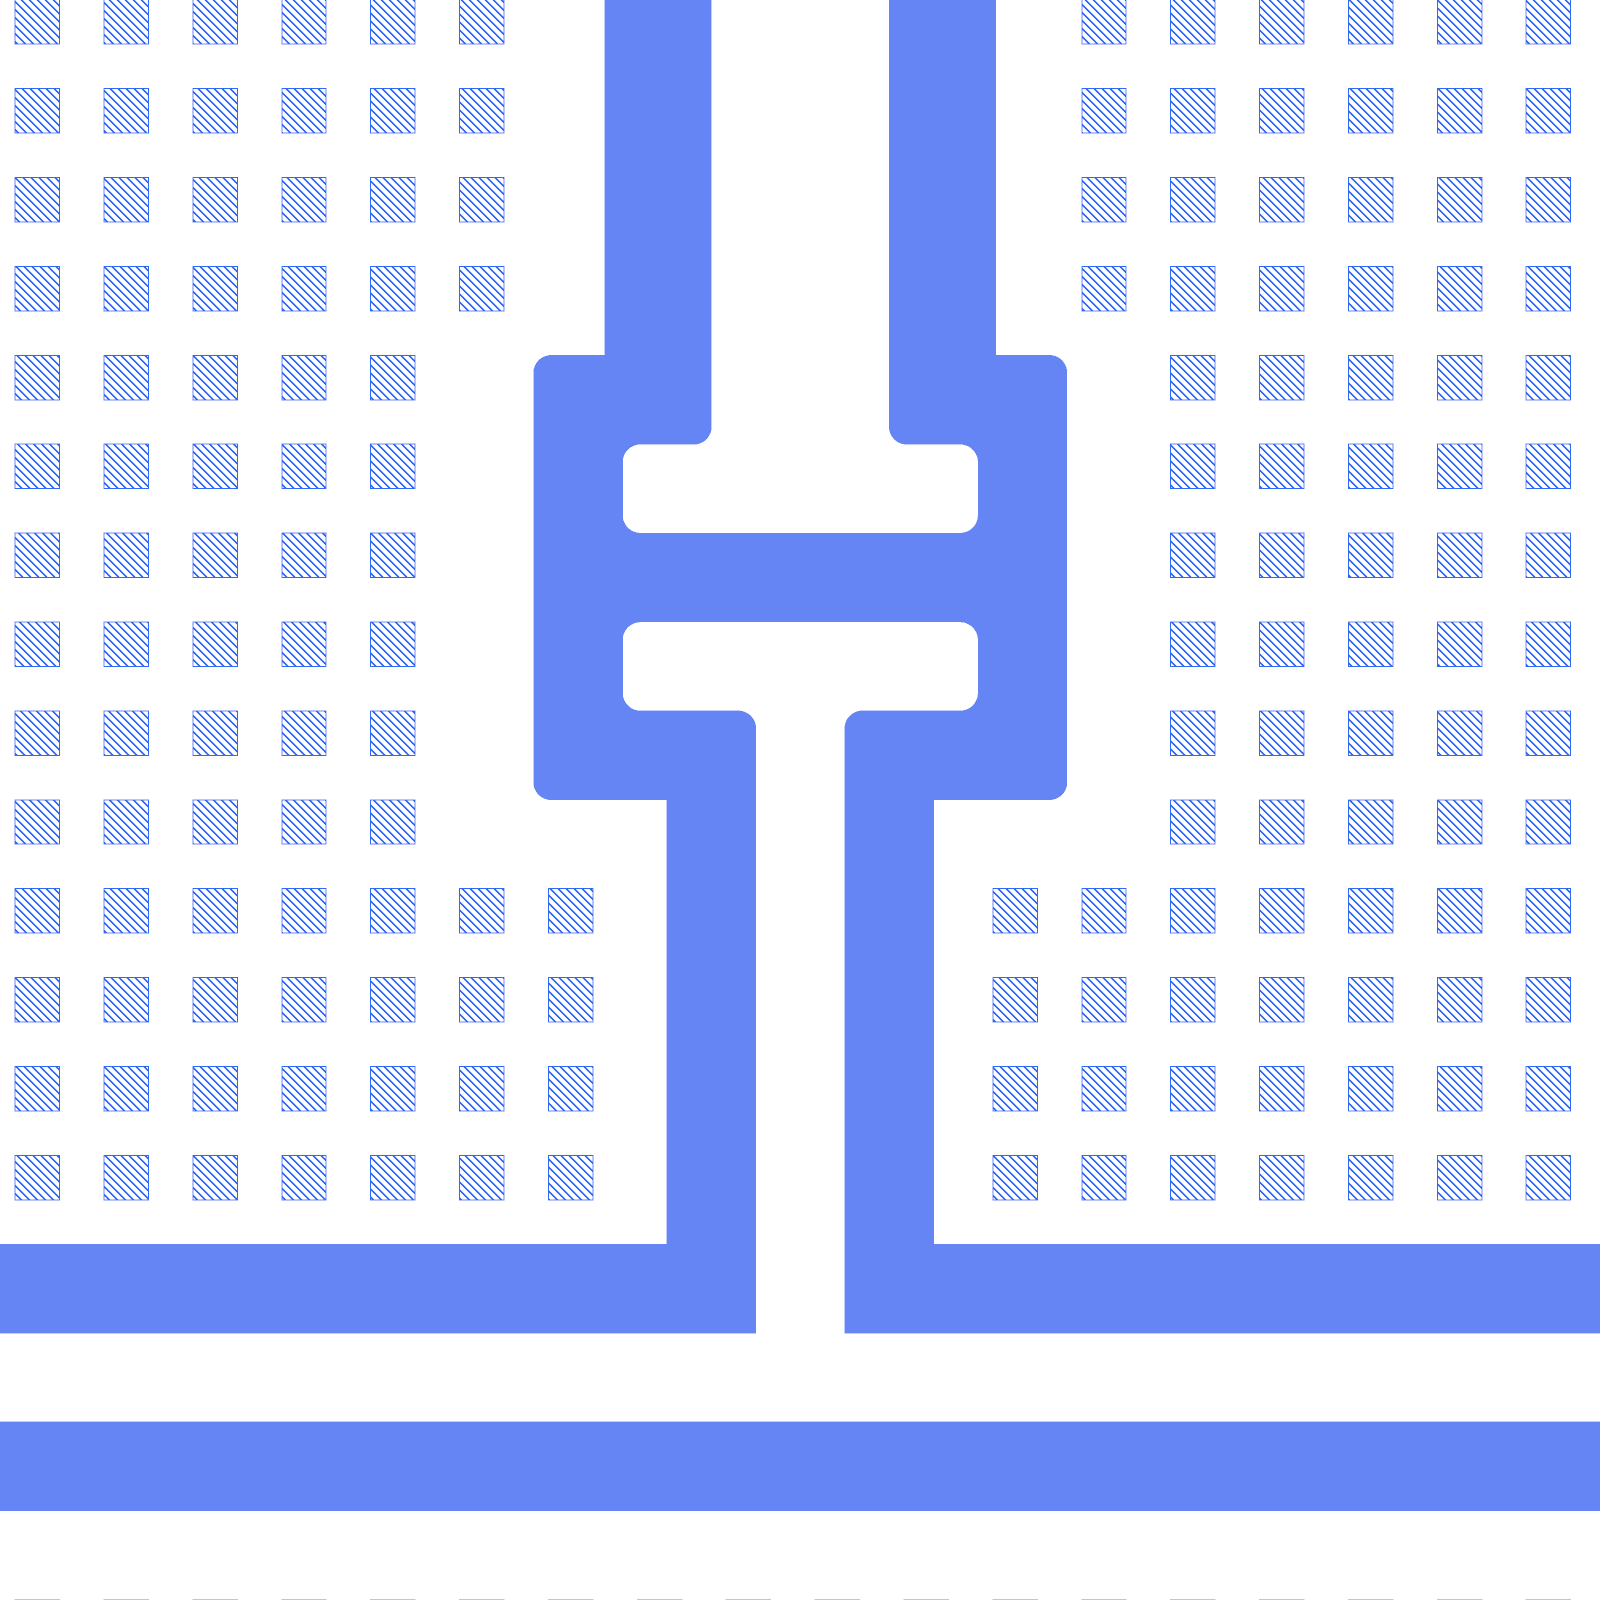

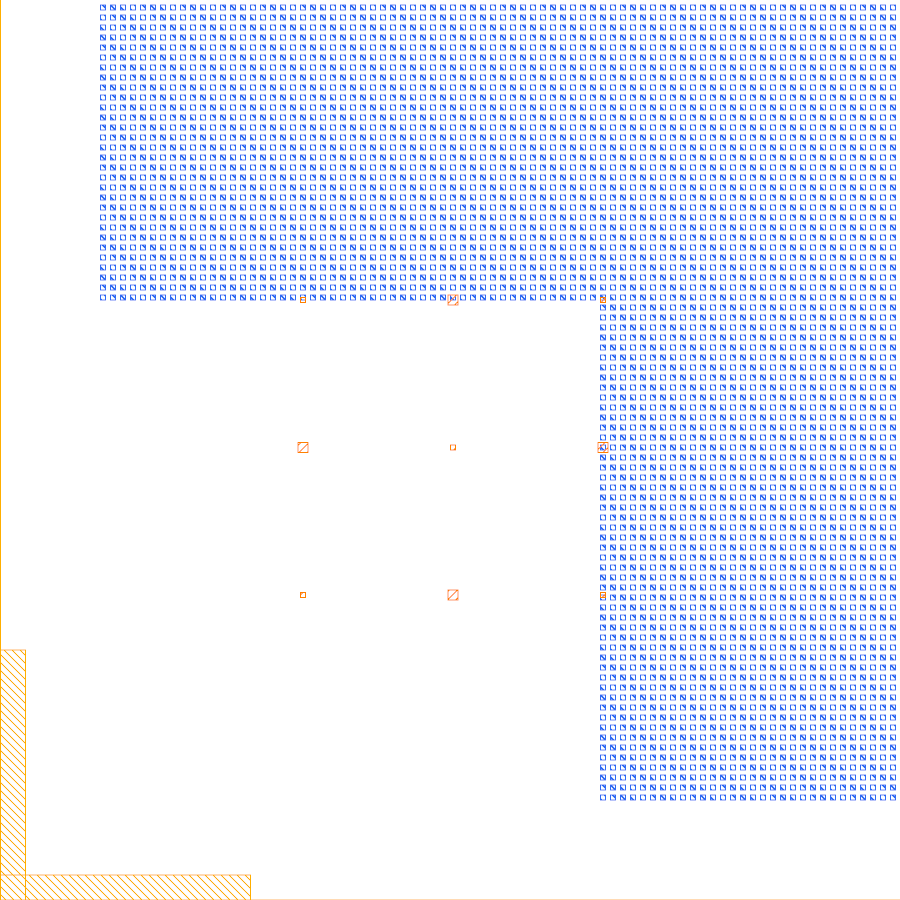

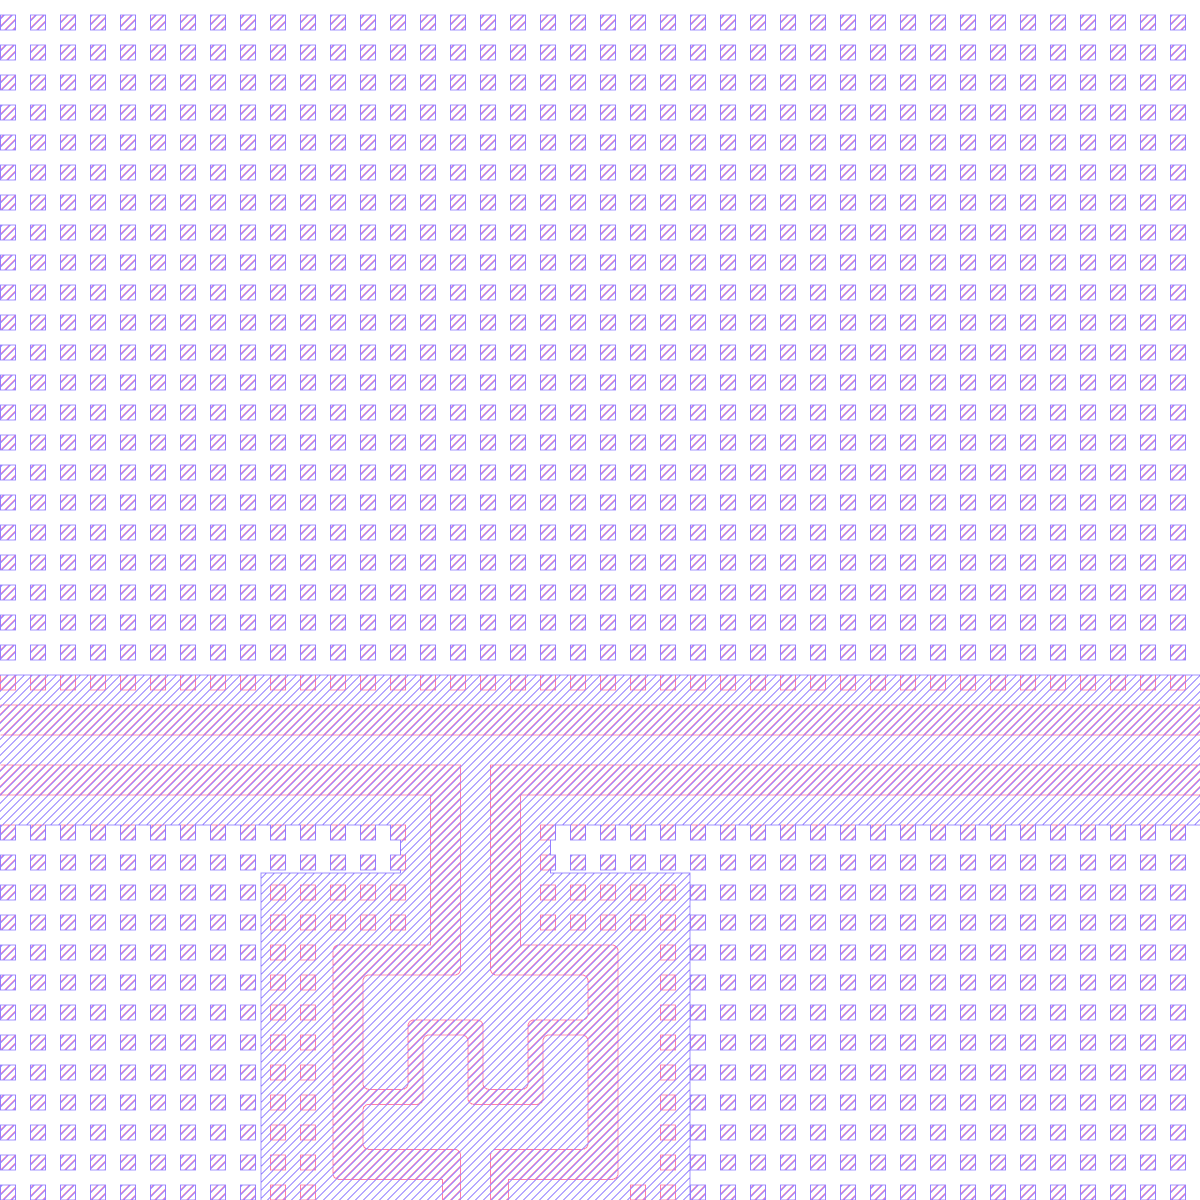

In [15]:
show_snapshot(d, OUT / "quality_factor_twoface.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "quality_factor_twoface_r0.png", box=(2600, 2750, 3400, 5100), size=(800, 1600), width=320)
x, y = port_xy(d, "T3.c")
show_snapshot(d, OUT / "quality_factor_twoface_c3.png", box=(x - 90, y - 90, x + 90, y + 90), width=360)
show_snapshot(d, OUT / "quality_factor_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "quality_factor_twoface_fab.oas", OUT / "quality_factor_twoface_fab.png", box=(3050, 4850, 3450, 5250), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers with their lines' first legs (80 µm deeper here). A reference, not a pass/fail check.

In [16]:
import klayout.db as kdb
from kqcircuits.chips.quality_factor_twoface import QualityFactorTwoface as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

| layer | XOR area (µm²) | > 1 nm (µm²) | where |
|---|---|---|---|
| 1t1_airbridge_flyover | 2.81e+05 | 2.81e+05 | (788,788;9212,9212) |
| 1t1_airbridge_pads | 5.4e+05 | 5.4e+05 | (788,788;9212,9212) |
| 1t1_base_metal_gap_for_EBL | 8.6e+06 | 8.6e+06 | (0,0;10000,10000) |
| 1t1_base_metal_gap_wo_grid | 8.66e+06 | 8.66e+06 | (0,0;10000,10000) |
| 1t1_chip_dicing | 2.68e+05 | 2.68e+05 | (-5,-5;10005,10005) |
| 1t1_ground_grid | 2.3e+07 | 2.3e+07 | (100,100;9895,9895) |
| 1t1_ground_grid_avoidance | 1.37e+07 | 1.37e+07 | (-5,-5;10005,10005) |
| 1t1_waveguide_path | 1.6e+03 | 1.6e+03 | (800,2851.9;9200,7205) |
| 2b1_airbridge_flyover | 2.62e+05 | 2.62e+05 | (2188,2188;7812,7812) |
| 2b1_airbridge_pads | 5.21e+05 | 5.21e+05 | (2188,2188;7812,7812) |
| 2b1_base_metal_gap_for_EBL | 4.58e+06 | 4.58e+06 | (1500,1500;8500,8500) |
| 2b1_base_metal_gap_wo_grid | 4.58e+06 | 4.58e+06 | (1500,1500;8500,8500) |
| 2b1_chip_dicing | 1.88e+05 | 1.88e+05 | (1495,1495;8505,8505) |
| 2b1_ground_grid_avoidance | 9.5e+06 | 9.5e+06 | (1495,1495;8505,8505) |
| qcc_chip_boundary | 1e+08 | 1e+08 | (0,0;10000,10000) |
| qcc_marker_0 | 4.75e+04 | 4.75e+04 | (0,0;10000,10000) |
| qcc_marker_1 | 2.1e+03 | 2.1e+03 | (297.5,300;9702.5,9700) |

**Total XOR area: 1.75e+08 µm²** (1.75e+08 µm² wider than 1 nm). Against KQC's default brand text "IQM": 1.75e+08 µm².

**Here:** the XOR (1.75 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer alone 1 × 10⁸ µm²), the ground grid and its avoidance, KQC's frames on both faces (on the lid the frame is all KQC draws: base etch 4.6 × 10⁶ µm²) and the launcher shift; the waveguide path differs by only 1.6 × 10³ µm² (the probe line's first legs).

## 15 · Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`); sapphire; KQC's grid on the bottom chip; no frame on the lid |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | 6 eigenmode jobs exported (`build/jobs/quality_factor_twoface_R*_eigenmode_epr`), not solved here |